# A Reservoir of Timescales in Random Neural Network

This notebook is associated with the following [article](https://arxiv.org/abs/2110.09165).

Underneath you can find a summary of the main results.

In [1]:
%%HTML
<iframe width="840" height="472.5" 
src="https://www.youtube.com/embed/Ab8kJYdnVBI" 
title="YouTube video player" frameborder="0" 
allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture" 
allowfullscreen></iframe>

We consider a population based rate model of a neural network. Our model consists of $N$ clusters of neurons. Mathematically, each cluster can be represented as a localized continuous variable $Q_{i}$, $i=1,2, ... ,N$ ranging between $Q_i(t) \in \left[-1.0,  1.0\right]$. Each cluster is associated with a local field $x_i(t)$ such that $Q_i(t) = \phi \left[ x_i(t) \right]$, where $\phi$ is an activation function that defines the input-output relationship for each cluster. Our model assumes a sigmoid shape activation function, we chose  $\phi\left[ \cdot \right] \equiv \tanh\left[ \cdot \right]$.
Biologically, $x_{i}(t)$ can be interpreted as the mean cluster activity, also known as the firing rate or population activity. The cluster properties are represented by a self-coupling term $s_i$  

The network is represented by a set of $N$ coupled ordinary differential equations:
$$
\frac{d}{dt}x_{i}(t) = - x_{i}(t) + s_i \phi \left[ x_i(t) \right]  + \sum_{j\neq i}^{N} J_{ij} \phi \left[ x_j(t) \right],
$$
the random couplings $J_{ij}$ from unit $j$ to unit $i$ are drawn independently from a Gaussian distribution with mean $0$ and variance $g^2/N$ where $g$ represents the network gain.
If we imagine a cluster of neurons as an electrical element. The left hand side describes the average change in the potential, the first term on the right hand side describes the average current leakage through the membrane of neurons, the second terms describes the average current due to the activity of neurons in the cluster scaled by a self-coupling parameter $s_i$ proportional to the number of neurons in the cluster. The last term on the right hand side describes the average current due to the activity of all other clusters. 

It is important to notice that the form of our coupled ODEs implies that time is a dimensionless parameter. In this model, we are using a homogeneous time constant $\theta_i = 1$ ms for all clusters.

Using [standard methods of statistical field theory](https://link.springer.com/book/10.1007/978-3-030-46444-8?noAccess=true), in the limit of large $N$ we can average over realizations of the disordered couplings $J_{ij}$ to derive a set of self-consistent dynamic mean field equations for each population of units $x_\alpha$ with self-coupling strengths $s_{\alpha} \in S$
\begin{equation}
\label{dmfteq1}
    \frac{dx_{\alpha}}{dt}=-x_{\alpha}+s_{\alpha}\tanh(x_{\alpha})+\eta(t)\ .
\end{equation}
In our notation, $S$ denotes the set of different values of self-couplings $s_\alpha$, indexed by $\alpha\in A$, and we denote by $N_\alpha$ the number of units with the same self-coupling $s_\alpha$, and accordingly by $n_\alpha=N_\alpha \big{/} N$ their fraction. The mean field $\eta(t)$ is the same for all units and has zero mean $\langle \eta(t)\rangle=0$ and autocorrelation

\begin{eqnarray}
    \langle \eta(t)&\eta&(t+\tau)\rangle=g^2C(\tau)\nonumber\\
    C(\tau)&=&\sum_{\alpha\in A } n_{\alpha} \langle \phi[x_{\alpha}(t)]\phi[x_{\alpha}(t+\tau)]\rangle \ ,     
    \label{dmfteq2}
\end{eqnarray}

where $\langle\cdot\rangle$ denotes an average over the mean field. 

When considering the large $N$ limit, that is a network with a large number of clusters, we simplified the large system to $card(S)$ ODEs that share a common term $\eta(t)$. This term can be thought of as the meanfield  background noise due to all the clusters. The dynamics described by each of these meanfield ODEs has its own autocorrelation function.

This result indicates that a total of $card(S)$ timescales are present in our network. We quantify the timescale of a cluster as the half width at half maximum (HWHM) of the normalised autocorrelation function $\left< \phi(x(t))\phi(x(t+\tau)) \right>$. The separation between the timescales depends on the self-couplings $s_{\alpha}$ and on the fraction $n_{lpha}$ of each subpopulation.

## Importing Packages

The local package `rnn_library` (folder `rnn_library/`) contains the network construction, the simulation and the autocorrelation/timescale analysis. Run this notebook from the repository root.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from rnn_library import (make_coupling_matrix, simulate, population_acfs,
                         timescales, population_slices)
from rnn_library.plotting import plot_acfs_with_traces

## Parameters

### Network Parameters

In [3]:
# We consider a network with
# 750 clusters with self-coupling 1.0 and
# 750 clusters with self-coupling 3.0
N_values = [750, 750]   # number of clusters in each population
s_values = [1.0, 3.0]   # self-coupling of each population
g = 2.0                 # network gain: off-diagonal J_ij ~ Normal(0, g^2 / N)

seed = 0                # fix for reproducible results; set to None for a fresh network

J_Matrix = make_coupling_matrix(N_values, s_values, g, rng=seed)
N = J_Matrix.shape[0]

### Simulation Parameters

In [4]:
t_end = 2000.0       # length of the recorded trajectory (ms)
dt = 0.1             # sampling interval (ms)
transient = 50.0     # time discarded at the start so the network forgets its initial condition (ms)

max_lag = 8000       # number of lags (in steps of dt) for the autocorrelation function (800 ms)

## Running the Simulation

In [5]:
# Solve dx/dt = -x + J tanh(x) from a random initial condition
t, x = simulate(J_Matrix, t_end, dt=dt, transient=transient, rng=seed)

# Autocorrelation <phi[x(t)] phi[x(t+tau)]>, phi = tanh, normalised per unit and
# averaged over each population; then the HWHM of each population's ACF
tau_timeline = np.arange(max_lag) * dt
C_phi_avg = population_acfs(x, N_values, max_lag=max_lag)
tau_values = timescales(tau_timeline, C_phi_avg)

for s, tau in zip(s_values, tau_values):
    print(f"s = {s:<4} timescale = {tau:6.2f} ms")

s = 1.0  timescale =  23.34 ms
s = 3.0  timescale =  42.92 ms


## Plotting Results

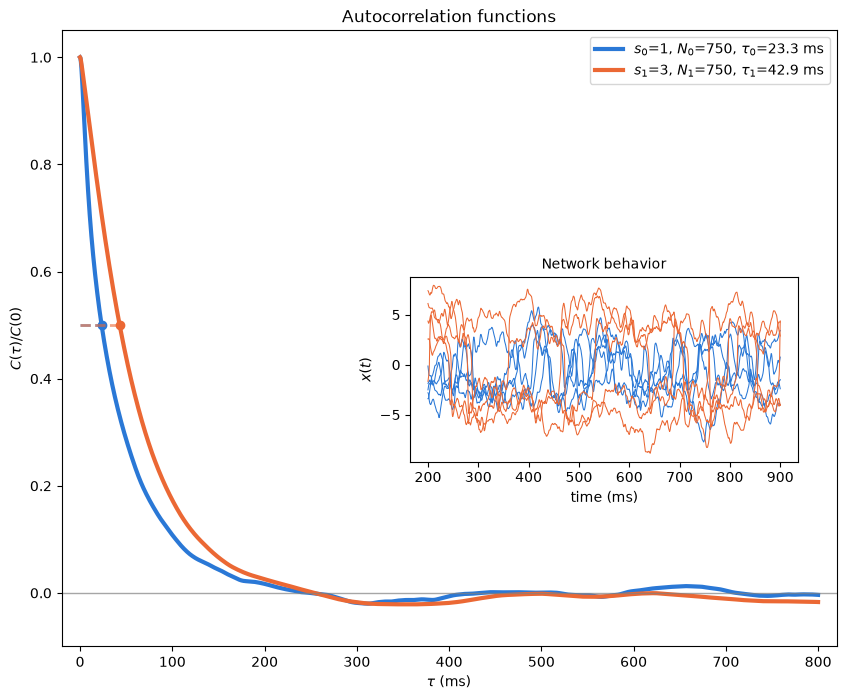

In [6]:
fig, ax = plot_acfs_with_traces(t, x, tau_timeline, C_phi_avg, N_values, s_values,
                                tau_values, rng=seed, xlim=(-20, 820))
plt.show()